# ML experiments: predicting a decline in patient-reported outcomes (PROs)


- Two binary outcomes: drop (at least a 10-point decline in `Overall`) and threshold(`Overall_end` at or below baseline mean minus one standard deviation).
- Eight base classifiers plus a soft-voting ensemble: LASSO, Ridge, Elastic Net, KNN, LightGBM, SVM, Random Forest, FFNN, and Ensemble Voting.
- Two imputation approaches: KNN imputation and median imputation with missingness indicators.
- Nested validation: hyperparameter tuning happens inside each training fold; the held-out fold is not used for tuning.
- Repeated stratified 5-fold CV, AUROC summaries, bootstrap confidence intervals, feature-group ablation, and LASSO coefficients.


In [ ]:

import importlib.util
import subprocess
import sys

if importlib.util.find_spec("lightgbm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lightgbm"])

print("Dependency check complete.")

Dependency check complete.


In [2]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
SEED = 42

# ------------------------- Editable run configuration -------------------------
DATA_FILENAME = "breast_pro_clean.csv"
CURRENT_DIR = Path.cwd().resolve()
SEARCH_ROOTS = [CURRENT_DIR, *list(CURRENT_DIR.parents)]

# Find the project root by looking for main/data/breast_pro_clean.csv.
# This works when Jupyter's working directory is either main/ or main/model/.
PROJECT_ROOT = next(
    (root for root in SEARCH_ROOTS if (root / "data" / DATA_FILENAME).is_file()),
    None,
)

# If the CSV is not uploaded yet, use the project root associated with a model/ folder,
# or the nearest ancestor that already has a data/ directory.
if PROJECT_ROOT is None:
    PROJECT_ROOT = next(
        (root.parent for root in SEARCH_ROOTS
         if root.name.lower() == "model" and (root.parent / "data").is_dir()),
        None,
    )
if PROJECT_ROOT is None:
    PROJECT_ROOT = next((root for root in SEARCH_ROOTS[:6] if (root / "data").is_dir()), None)
if PROJECT_ROOT is None:
    PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name.lower() == "model" else CURRENT_DIR

DATA_DIR = PROJECT_ROOT / "data"
DATA_PATH = DATA_DIR / DATA_FILENAME
OUTPUT_DIR = PROJECT_ROOT / "outfolder"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

REPEATS = 1              # Use more to repeat
N_JOBS = 1               # Use 2 or more for outer-fold parallelism if your machine allows it
BOOTSTRAP_N = 2000       # Number of bootstrap draws for 95% CIs
RUN_ABLATION = True
RUN_LASSO_INTERPRETATION = True

print(f"Current working directory: {CURRENT_DIR}")
print(f"Project root: {PROJECT_ROOT}")
print(f"Data path expected: {DATA_PATH}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Repeated 5-fold CV repeats: {REPEATS}; outer-fold jobs: {N_JOBS}")


Current working directory: C:\Users\prajw\OneDrive\Documents\5 sem\ML\predicting-decline-patient-reported-outcomes\model
Project root: C:\Users\prajw\OneDrive\Documents\5 sem\ML\predicting-decline-patient-reported-outcomes
Data path expected: C:\Users\prajw\OneDrive\Documents\5 sem\ML\predicting-decline-patient-reported-outcomes\data\breast_pro_clean.csv
Output directory: C:\Users\prajw\OneDrive\Documents\5 sem\ML\predicting-decline-patient-reported-outcomes\outfolder
Repeated 5-fold CV repeats: 1; outer-fold jobs: 1


In [3]:
#  Load data

if not DATA_PATH.is_file():
    fallback = next(
        (root / DATA_FILENAME for root in SEARCH_ROOTS if (root / DATA_FILENAME).is_file()),
        None,
    )
    if fallback is not None:
        DATA_PATH = fallback

# In Google Colab, offer an upload prompt if the file was not found locally.
if not DATA_PATH.is_file():
    try:
        from google.colab import files
        print(f"Upload {DATA_FILENAME}. It will be saved into: {DATA_DIR}")
        uploaded = files.upload()
        if DATA_FILENAME in uploaded:
            DATA_DIR.mkdir(parents=True, exist_ok=True)
            DATA_PATH.write_bytes(uploaded[DATA_FILENAME])
    except ImportError:
        pass

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILENAME}. Expected it at {PROJECT_ROOT / 'data' / DATA_FILENAME}. "
        "Keep the CSV in main/data/ and the notebook in main/model/, or edit DATA_PATH in the configuration cell."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset: {DATA_PATH.resolve()}")
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())
print("\nMissing values in columns with missing data:")
missing_counts = df.isna().sum()
display(missing_counts[missing_counts > 0].sort_values(ascending=False).to_frame("missing_count"))


Loaded dataset: C:\Users\prajw\OneDrive\Documents\5 sem\ML\predicting-decline-patient-reported-outcomes\data\breast_pro_clean.csv
Dataset shape: 219 rows × 57 columns


,ID,HE_baseline,PH_baseline,RO_baseline,EF_baseline,COG_baseline,SO_baseline,FA_baseline,NA_baseline,PA_baseline,...,HER2,Marital_status,Perceived_risk_recurrence,Surgery_clin_normalized,Surgery_mismatch,Surgery_review_status,Overall_change,Decline_10,HE_change,HE_decline_10
0,8,58.3,73.3,83.3,58.3,83.3,66.7,55.6,0.0,16.7,...,Negative,Married/partnered,High,BCS,0,MATCH,24.76,0.0,25.0,0.0
1,14,83.3,100.0,100.0,91.7,100.0,100.0,22.2,0.0,0.0,...,Positive,Married/partnered,High,BCS,0,MATCH,0.14,0.0,0.0,0.0
2,22,66.7,80.0,66.7,91.7,83.3,100.0,33.3,0.0,0.0,...,Negative,Married/partnered,Very high,Mastectomy,0,MATCH,-45.15,1.0,-66.7,1.0
3,23,50.0,86.7,50.0,50.0,50.0,33.3,66.7,0.0,66.7,...,Positive,Married/partnered,High,Mastectomy,0,MATCH,-16.12,1.0,-33.3,1.0
4,25,83.3,86.7,100.0,100.0,100.0,100.0,44.4,0.0,0.0,...,Negative,Single,Very high,Mastectomy,0,MATCH,-13.82,1.0,-33.3,1.0



Missing values in columns with missing data:


,missing_count
HE_baseline,2
CO_baseline,2
HE_decline_10,2
HE_change,2
Children,1
SYM_baseline,1


In [4]:
#  Feature engineering 
base_scales = [c for c in df.columns if c.endswith("_baseline")]
required_cols = [
    "Overall_baseline", "Overall_end", "Age", "TNM_stage", "ECOG", "HER2",
    "Chemotherapy_regimen", "Radiotherapy", "Axillary_lymphadenectomy",
    "Surgery_qlq", "Educational_level", "Children", "Perceived_risk_recurrence",
    "Occupational_status", "Marital_status",
]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise ValueError(f"The dataset is missing required columns: {missing_required}")
if not base_scales:
    raise ValueError("No baseline PRO columns ending in '_baseline' were found.")

X = pd.DataFrame(index=df.index)
for c in base_scales:
    X[c] = df[c]

# Clinical features known before chemotherapy
X["Age"] = df["Age"]
X["TNM_stage"] = df["TNM_stage"].map({"I": 1, "II": 2, "III": 3})
X["ECOG"] = df["ECOG"]
X["HER2_pos"] = (df["HER2"] == "Positive").astype(int)
X["Anthracycline"] = (df["Chemotherapy_regimen"] == "Anthracycline").astype(int)
X["Radiotherapy"] = (df["Radiotherapy"] == "Yes").astype(int)
X["Axillary_lymphadenectomy"] = (df["Axillary_lymphadenectomy"] == "Yes").astype(int)
X["Mastectomy"] = (df["Surgery_qlq"] == "Mastectomy").astype(int)

# Socio-demographic features
X["Education_secondary_plus"] = (df["Educational_level"] == "Secondary or higher education").astype(int)
X["Children"] = df["Children"]
X["Perceived_risk"] = df["Perceived_risk_recurrence"].map(
    {"Low": 1, "Medium": 2, "High": 3, "Very high": 4}
)
for col in ["Occupational_status", "Marital_status"]:
    dummies = pd.get_dummies(df[col], prefix=col, drop_first=True).astype(int)
    X = pd.concat([X, dummies], axis=1)

soc_cols = ["Education_secondary_plus", "Children", "Perceived_risk"] + [
    c for c in X.columns
    if c.startswith(("Occupational_status_", "Marital_status_"))
]
clin_cols = [
    "Age", "TNM_stage", "ECOG", "HER2_pos", "Anthracycline", "Radiotherapy",
    "Axillary_lymphadenectomy", "Mastectomy",
]
GROUPS = {
    "baseline PRO scores": base_scales,
    "clinical": clin_cols,
    "socio-demographic": soc_cols,
}
ALL = base_scales + clin_cols + soc_cols

if len(ALL) != len(set(ALL)):
    raise ValueError("Duplicate feature names were created.")

# Outcomes (definitions retained from the supplied script)
thr = df["Overall_baseline"].mean() - df["Overall_baseline"].std()
outcomes = {
    "drop": (df["Overall_end"] - df["Overall_baseline"] <= -10),
    "threshold": (df["Overall_end"] <= thr),
}
valid = df["Overall_end"].notna() & df["Overall_baseline"].notna()

print(f"Patients with usable outcome: {int(valid.sum())} / {len(df)}")
print(f"Threshold (mean - 1 SD of Overall_baseline): {thr:.2f}")
for outcome_name, labels in outcomes.items():
    y_valid = labels.loc[valid].astype(int)
    positives = int(y_valid.sum())
    negatives = int(len(y_valid) - positives)
    print(f"{outcome_name:10s}: {positives} positives, {negatives} negatives ({y_valid.mean()*100:.1f}% positive)")

print(f"\nNumber of baseline PRO features: {len(base_scales)}")
print(f"Number of clinical features: {len(clin_cols)}")
print(f"Number of socio-demographic features: {len(soc_cols)}")
print(f"Total model features: {len(ALL)}")
display(X[ALL].describe().T)

Patients with usable outcome: 219 / 219
Threshold (mean - 1 SD of Overall_baseline): 60.12
drop      : 64 positives, 155 negatives (29.2% positive)
threshold : 57 positives, 162 negatives (26.0% positive)

Number of baseline PRO features: 17
Number of clinical features: 8
Number of socio-demographic features: 5
Total model features: 30


,count,mean,std,min,25%,50%,75%,max
HE_baseline,217.0,70.623502,18.701469,0.00,58.300,66.70,83.300,100.00
PH_baseline,219.0,86.113242,14.635453,40.00,73.300,93.30,100.000,100.00
RO_baseline,219.0,75.955708,25.338693,0.00,66.700,83.30,100.000,100.00
EF_baseline,219.0,69.574429,25.692170,0.00,50.000,75.00,91.700,100.00
COG_baseline,219.0,84.092694,21.040157,0.00,66.700,100.00,100.000,100.00
SO_baseline,219.0,75.572146,25.700541,0.00,66.700,83.30,100.000,100.00
FA_baseline,219.0,28.806393,24.002025,0.00,11.100,22.20,44.400,100.00
NA_baseline,219.0,9.059817,16.980986,0.00,0.000,0.00,16.700,100.00
PA_baseline,219.0,19.862557,25.185041,0.00,0.000,16.70,33.300,100.00
DY_baseline,219.0,4.868037,15.851501,0.00,0.000,0.00,0.000,100.00


In [5]:
#  Model definitions 
def make_imputer(kind):
    return KNNImputer(n_neighbors=5) if kind == "knn" else SimpleImputer(strategy="median", add_indicator=True)

C_GRID = [0.01, 0.03, 0.1, 0.3, 1, 3, 10]
MODELS = {
    "LASSO": (
        LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=3000),
        {"clf__C": C_GRID},
    ),
    "Ridge": (
        LogisticRegression(l1_ratio=0, max_iter=3000),
        {"clf__C": C_GRID},
    ),
    "Elastic Net": (
        LogisticRegression(solver="saga", max_iter=5000),
        {"clf__C": C_GRID, "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 10, 20, 40], "clf__weights": ["uniform", "distance"]},
    ),
    "LightGBM": (
        LGBMClassifier(
            n_estimators=150, verbose=-1, subsample=0.8, subsample_freq=1,
            colsample_bytree=0.8, min_child_samples=10, random_state=SEED, n_jobs=1,
        ),
        {"clf__learning_rate": [0.02, 0.05, 0.1], "clf__num_leaves": [3, 7]},
    ),
    "SVM": (
        SVC(probability=True, random_state=SEED),
        {"clf__C": [0.1, 1, 10], "clf__kernel": ["linear", "poly", "rbf", "sigmoid"]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
        {"clf__min_samples_split": [2, 5, 10, 20], "clf__max_features": ["sqrt", None]},
    ),
    "FFNN": (
        MLPClassifier(
            max_iter=500, early_stopping=True, validation_fraction=0.15,
            n_iter_no_change=10, random_state=SEED,
        ),
        {"clf__hidden_layer_sizes": [(16, 8), (32, 16)], "clf__alpha": [1e-3, 1e-1, 10.0]},
    ),
}
ENSEMBLE_MEMBERS = ["LASSO", "Ridge", "Elastic Net", "Random Forest", "LightGBM", "SVM"]
ALL_MODELS = list(MODELS) + ["Ensemble Voting"]

print("Models:", ", ".join(ALL_MODELS))

Models: LASSO, Ridge, Elastic Net, KNN, LightGBM, SVM, Random Forest, FFNN, Ensemble Voting


In [6]:
# Validation and evaluation helpers 
def fit_predict_fold(Xtr, ytr, Xte, imputer_kind, model_names, seed):
    """Tune on the outer training fold only, then predict its held-out fold."""
    need = set(model_names)
    if "Ensemble Voting" in need:
        need |= set(ENSEMBLE_MEMBERS)
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    preds = {}

    for name in MODELS:
        if name not in need:
            continue
        estimator, grid = MODELS[name]
        pipe = Pipeline([
            ("imp", make_imputer(imputer_kind)),
            ("sc", StandardScaler()),
            ("clf", clone(estimator)),
        ])
        search = GridSearchCV(
            pipe, grid, cv=inner, scoring="roc_auc", n_jobs=1, refit=True,
        )
        search.fit(Xtr, ytr)
        preds[name] = search.predict_proba(Xte)[:, 1]

    if "Ensemble Voting" in need:
        preds["Ensemble Voting"] = np.mean([preds[m] for m in ENSEMBLE_MEMBERS], axis=0)
    return {k: v for k, v in preds.items() if k in model_names}


def run_cv(cols, outcome, imputer_kind, model_names, repeats=REPEATS, n_jobs=N_JOBS):
    """Repeated stratified outer 5-fold CV with inner 5-fold hyperparameter tuning."""
    Xv = X.loc[valid, cols].reset_index(drop=True)
    yv = outcomes[outcome].loc[valid].astype(int).reset_index(drop=True).to_numpy()
    class_counts = np.bincount(yv, minlength=2)
    if class_counts.min() < 5:
        raise ValueError(f"Outcome '{outcome}' needs at least 5 examples in each class; found {class_counts.tolist()}.")

    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats, random_state=SEED)
    splits = list(cv.split(Xv, yv))
    fold_predictions = Parallel(n_jobs=n_jobs)(
        delayed(fit_predict_fold)(
            Xv.iloc[train_idx], yv[train_idx], Xv.iloc[test_idx],
            imputer_kind, model_names, SEED + fold_idx,
        )
        for fold_idx, (train_idx, test_idx) in enumerate(splits)
    )

    fold_auc = {model: [] for model in model_names}
    oof = {model: np.full((repeats, len(yv)), np.nan) for model in model_names}
    for fold_idx, ((train_idx, test_idx), predictions) in enumerate(zip(splits, fold_predictions)):
        repeat_idx = fold_idx // 5
        for model in model_names:
            fold_auc[model].append(roc_auc_score(yv[test_idx], predictions[model]))
            oof[model][repeat_idx, test_idx] = predictions[model]
    return fold_auc, oof, yv


def bootstrap_ci(y, probabilities, n=BOOTSTRAP_N, seed=0):
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n):
        indices = rng.integers(0, len(y), len(y))
        if len(np.unique(y[indices])) == 2:
            aucs.append(roc_auc_score(y[indices], probabilities[indices]))
    if not aucs:
        return np.nan, np.nan
    return np.percentile(aucs, [2.5, 97.5])


def summarize(fold_auc, oof, yv):
    summary = {}
    for model in fold_auc:
        pooled = np.nanmean(oof[model], axis=0)  # average repeated OOF predictions per patient
        ci_low, ci_high = bootstrap_ci(yv, pooled)
        summary[model] = {
            "auc_mean": float(np.mean(fold_auc[model])),
            "auc_sd": float(np.std(fold_auc[model])),
            "pooled_auc": float(roc_auc_score(yv, pooled)),
            "ci_lo": float(ci_low),
            "ci_hi": float(ci_high),
        }
    return summary

print("Evaluation helpers defined.")

Evaluation helpers defined.


## Experiment 1 — model comparison

This section compares every model for both outcomes and both imputation methods. The outer test fold is not used for hyperparameter tuning.

In [7]:
t0 = time.time()
rows = []
saved_oof = {}

for outcome_name in outcomes:
    for imp_label in ["knn", "median+indicator"]:
        imputer_kind = "knn" if imp_label == "knn" else "median"
        fold_auc, oof_predictions, y_valid = run_cv(
            ALL, outcome_name, imputer_kind, ALL_MODELS,
            repeats=REPEATS, n_jobs=N_JOBS,
        )
        summary = summarize(fold_auc, oof_predictions, y_valid)
        for model_name, metrics in summary.items():
            rows.append({
                "outcome": outcome_name,
                "imputation": imp_label,
                "model": model_name,
                **metrics,
            })
        saved_oof[(outcome_name, imp_label)] = (oof_predictions, y_valid)
        top_model = max(summary, key=lambda name: summary[name]["auc_mean"])
        print(
            f"[{time.time() - t0:6.0f}s] {outcome_name:9s} {imp_label:17s} "
            f"best={top_model:16s} AUROC={summary[top_model]['auc_mean']:.3f}"
        )

results = pd.DataFrame(rows)
results_path = OUTPUT_DIR / "exp1_model_comparison.csv"
results.to_csv(results_path, index=False)

# Save pooled out-of-fold predictions for ROC plots and further analysis.
npz_data = {}
for (outcome_name, imp_label), (oof_predictions, y_valid) in saved_oof.items():
    for model_name, predictions in oof_predictions.items():
        npz_data[f"{outcome_name}|{imp_label}|{model_name}"] = np.nanmean(predictions, axis=0)
    npz_data[f"{outcome_name}|{imp_label}|y"] = y_valid
np.savez(OUTPUT_DIR / "oof_predictions.npz", **npz_data)

print(f"\nExperiment 1 complete in {(time.time() - t0) / 60:.1f} minutes.")
print(f"Saved: {results_path.resolve()}")
display(
    results.sort_values(["outcome", "auc_mean"], ascending=[True, False])
    .reset_index(drop=True)
)

[   138s] drop      knn               best=Elastic Net      AUROC=0.688
[   268s] drop      median+indicator  best=Elastic Net      AUROC=0.682
[   405s] threshold knn               best=SVM              AUROC=0.797
[   542s] threshold median+indicator  best=SVM              AUROC=0.787

Experiment 1 complete in 9.0 minutes.
Saved: C:\Users\prajw\OneDrive\Documents\5 sem\ML\predicting-decline-patient-reported-outcomes\outfolder\exp1_model_comparison.csv


,outcome,imputation,model,auc_mean,auc_sd,pooled_auc,ci_lo,ci_hi
0,drop,knn,Elastic Net,0.687758,0.066932,0.667591,0.587420,0.743772
1,drop,median+indicator,Elastic Net,0.682175,0.063090,0.658216,0.576011,0.737356
2,drop,median+indicator,Ensemble Voting,0.680893,0.082517,0.673085,0.588571,0.750970
3,drop,median+indicator,Ridge,0.679777,0.084597,0.650605,0.563920,0.731634
4,drop,knn,Ridge,0.678825,0.079542,0.667843,0.585212,0.748776
5,drop,knn,KNN,0.677998,0.110514,0.660333,0.578834,0.738158
6,drop,median+indicator,KNN,0.677916,0.125163,0.655292,0.573032,0.735184
7,drop,knn,Ensemble Voting,0.675889,0.077132,0.672177,0.589498,0.753074
8,drop,knn,LASSO,0.671050,0.074299,0.676210,0.592791,0.754788
9,drop,median+indicator,LASSO,0.671009,0.075995,0.674698,0.592680,0.751729


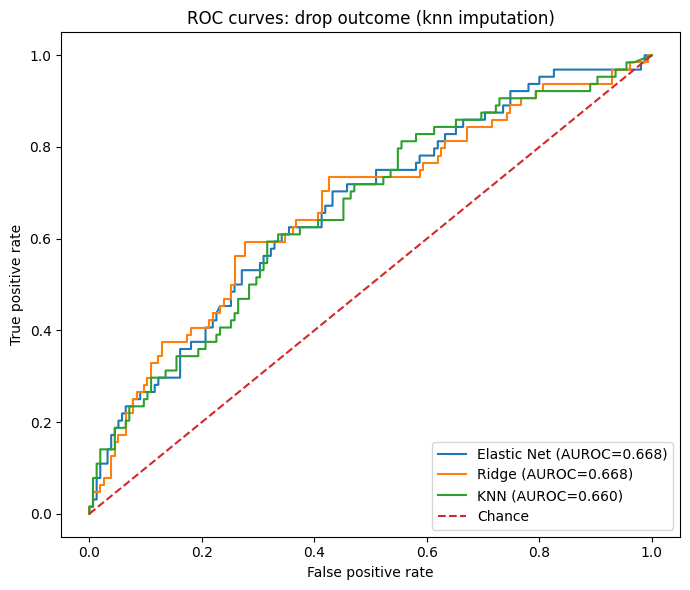

In [8]:
# Optional visual summary: ROC curves for the top three models for the 'drop' outcome.
drop_results = results[results["outcome"] == "drop"].sort_values("auc_mean", ascending=False)
best_imputation_for_drop = drop_results.iloc[0]["imputation"]
top_models = (
    drop_results[drop_results["imputation"] == best_imputation_for_drop]
    .sort_values("auc_mean", ascending=False)["model"]
    .drop_duplicates()
    .head(3)
    .tolist()
)

saved = np.load(OUTPUT_DIR / "oof_predictions.npz")
y_plot = saved[f"drop|{best_imputation_for_drop}|y"]
plt.figure(figsize=(7, 6))
for model_name in top_models:
    p = saved[f"drop|{best_imputation_for_drop}|{model_name}"]
    fpr, tpr, _ = roc_curve(y_plot, p)
    area = roc_auc_score(y_plot, p)
    plt.plot(fpr, tpr, label=f"{model_name} (AUROC={area:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"ROC curves: drop outcome ({best_imputation_for_drop} imputation)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Experiment 2 — feature-group ablation

The best model/imputation combination for the `drop` outcome is selected by mean outer-fold AUROC, then retrained and evaluated under feature subsets.

In [9]:
ablation_results = None
if RUN_ABLATION:
    drop_table = results[results["outcome"] == "drop"]
    best_row = drop_table.loc[drop_table["auc_mean"].idxmax()]
    best_model = best_row["model"]
    best_imp = best_row["imputation"]
    imputer_kind = "knn" if best_imp == "knn" else "median"
    print(f"Ablation model: {best_model} | imputation: {best_imp} | outcome: drop")

    configs = {"Full model (all features)": ALL}
    for group_name, columns in GROUPS.items():
        configs[f"Without {group_name}"] = [c for c in ALL if c not in columns]
    configs["Baseline PRO scores only"] = base_scales
    configs["Baseline overall score only"] = ["Overall_baseline"]
    configs["Clinical + socio-demographic only"] = clin_cols + soc_cols

    ablation_rows = []
    for config_name, columns in configs.items():
        fold_auc, oof_predictions, y_valid = run_cv(
            columns, "drop", imputer_kind, [best_model],
            repeats=REPEATS, n_jobs=N_JOBS,
        )
        metrics = summarize(fold_auc, oof_predictions, y_valid)[best_model]
        ablation_rows.append({
            "config": config_name,
            "n_features": len(columns),
            **metrics,
        })
        print(f"{config_name:38s} AUROC={metrics['auc_mean']:.3f}")

    ablation_results = pd.DataFrame(ablation_rows).sort_values("auc_mean", ascending=False)
    ablation_path = OUTPUT_DIR / "exp2_ablation.csv"
    ablation_results.to_csv(ablation_path, index=False)
    print(f"Saved: {ablation_path.resolve()}")
    display(ablation_results.reset_index(drop=True))
else:
    print("Ablation skipped. Set RUN_ABLATION = True in the configuration cell to enable it.")

Ablation model: Elastic Net | imputation: knn | outcome: drop
Full model (all features)              AUROC=0.688
Without baseline PRO scores            AUROC=0.605
Without clinical                       AUROC=0.645
Without socio-demographic              AUROC=0.678
Baseline PRO scores only               AUROC=0.647
Baseline overall score only            AUROC=0.640
Clinical + socio-demographic only      AUROC=0.605
Saved: C:\Users\prajw\OneDrive\Documents\5 sem\ML\predicting-decline-patient-reported-outcomes\outfolder\exp2_ablation.csv


,config,n_features,auc_mean,auc_sd,pooled_auc,ci_lo,ci_hi
0,Full model (all features),30,0.687758,0.066932,0.667591,0.587420,0.743772
1,Without socio-demographic,25,0.678495,0.066135,0.654486,0.573575,0.731961
2,Baseline PRO scores only,17,0.646629,0.071062,0.619153,0.534128,0.695660
3,Without clinical,22,0.644624,0.076024,0.628478,0.548217,0.705731
4,Baseline overall score only,1,0.640054,0.110036,0.626210,0.543954,0.704486
5,Without baseline PRO scores,13,0.605273,0.040518,0.604889,0.520989,0.686974
6,Clinical + socio-demographic only,13,0.605273,0.040518,0.604889,0.520989,0.686974


## Interpretation — LASSO coefficients

LASSO is fitted on the usable rows after selecting its regularization strength with 5-fold CV. These coefficients are descriptive associations from the fitted model, not causal effects. For a final report, prefer coefficients and performance estimates from the cross-validation procedure, and interpret the small sample size cautiously.

In [10]:
lasso_coefficients = None
if RUN_LASSO_INTERPRETATION:
    # Use the imputation approach with the highest mean AUROC for the 'drop' outcome.
    drop_table = results[results["outcome"] == "drop"]
    selected_row = drop_table.loc[drop_table["auc_mean"].idxmax()]
    selected_imputation = selected_row["imputation"]
    imputer_kind = "knn" if selected_imputation == "knn" else "median"

    X_valid = X.loc[valid, ALL].reset_index(drop=True)
    y_valid = outcomes["drop"].loc[valid].astype(int).to_numpy()
    estimator, grid = MODELS["LASSO"]
    pipeline = Pipeline([
        ("imp", make_imputer(imputer_kind)),
        ("sc", StandardScaler()),
        ("clf", clone(estimator)),
    ])
    search = GridSearchCV(
        pipeline, grid,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
        scoring="roc_auc", n_jobs=1,
    ).fit(X_valid, y_valid)

    feature_names = list(ALL)
    if imputer_kind != "knn":
        feature_names += [f"missing:{c}" for c in X_valid.columns[X_valid.isna().any()]]
    coefficients = search.best_estimator_.named_steps["clf"].coef_[0]
    feature_names = feature_names[:len(coefficients)]
    lasso_coefficients = pd.DataFrame({"feature": feature_names, "coef": coefficients})
    lasso_coefficients = lasso_coefficients[lasso_coefficients["coef"] != 0].copy()
    lasso_coefficients["abs_coef"] = lasso_coefficients["coef"].abs()
    lasso_coefficients = lasso_coefficients.sort_values("abs_coef", ascending=False)
    lasso_path = OUTPUT_DIR / "lasso_coefficients.csv"
    lasso_coefficients.drop(columns="abs_coef").to_csv(lasso_path, index=False)

    print(f"Selected imputation: {selected_imputation}")
    print(f"Best LASSO C: {search.best_params_['clf__C']}")
    print(f"Saved: {lasso_path.resolve()}")
    display(lasso_coefficients.head(20).drop(columns="abs_coef"))
else:
    print("LASSO interpretation skipped. Set RUN_LASSO_INTERPRETATION = True to enable it.")

Selected imputation: knn
Best LASSO C: 0.3
Saved: C:\Users\prajw\OneDrive\Documents\5 sem\ML\predicting-decline-patient-reported-outcomes\outfolder\lasso_coefficients.csv


,feature,coef
20,HER2_pos,0.363870
6,FA_baseline,-0.339999
19,ECOG,0.325500
12,CO_baseline,0.314758
1,PH_baseline,0.308161
24,Mastectomy,0.293803
7,NA_baseline,-0.244531
28,Occupational_status_Not employed,0.158477
4,COG_baseline,0.125824
2,RO_baseline,0.079847


## Files produced

All output files are saved in `main/outfolder/` (the `outfolder/` directory is created automatically at the project root).

When the corresponding sections have run, the folder contains:

- `exp1_model_comparison.csv` — model/outcome/imputation AUROC summaries and bootstrap intervals.
- `oof_predictions.npz` — pooled out-of-fold probabilities and labels for ROC curves.
- `exp2_ablation.csv` — feature-group ablation results (if enabled).
- `lasso_coefficients.csv` — non-zero standardized LASSO coefficients (if enabled).
